In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/lung_cancer_examples.csv")
df

,Name,Surname,Age,Smokes,AreaQ,Alcohol,Result
0,John,Wick,35,3,5,4,1
1,Emma,Stone,28,0,3,1,0
2,Rahul,Sharma,45,15,7,6,1
3,Anu,Nair,22,0,2,0,0
4,David,Miller,50,20,8,7,1
5,Sophia,Lee,31,2,4,2,0
6,Arjun,Das,60,25,9,8,1
7,Maria,Jose,27,1,3,1,0
8,Kevin,Paul,40,10,6,5,1
9,Neha,Roy,24,0,2,0,0


In [ ]:
df.shape

(20, 7)

In [ ]:
df.dtypes

,0
Name,object
Surname,object
Age,int64
Smokes,int64
AreaQ,int64
Alcohol,int64
Result,int64


In [ ]:
df.isna().sum()

,0
Name,0
Surname,0
Age,0
Smokes,0
AreaQ,0
Alcohol,0
Result,0


In [ ]:
df.duplicated().sum()

np.int64(0)

<Axes: >

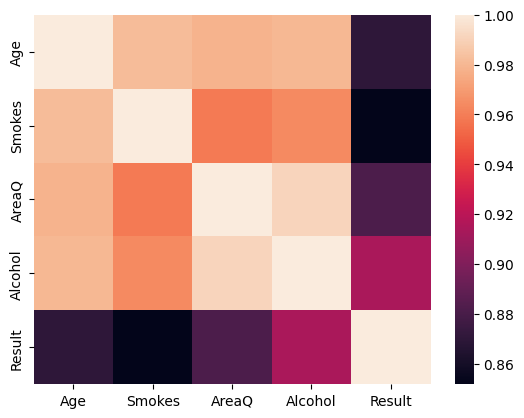

In [ ]:
sns.heatmap(df.corr(numeric_only=True))

In [ ]:
x = df.drop(columns=['Name', 'Surname','Result'])
x.ndim
x

,Age,Smokes,AreaQ,Alcohol
0,35,3,5,4
1,28,0,3,1
2,45,15,7,6
3,22,0,2,0
4,50,20,8,7
5,31,2,4,2
6,60,25,9,8
7,27,1,3,1
8,40,10,6,5
9,24,0,2,0


In [ ]:
y = df['Result']
y.ndim
y

,Result
0,1
1,0
2,1
3,0
4,1
5,0
6,1
7,0
8,1
9,0


In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.20, random_state=1)

In [ ]:
df['Result'].value_counts()

,count
Result,
1,10
0,10


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [ ]:
x_train

array([[ 0.65212285,  0.73079405,  0.8510645 ,  0.91287093],
       [ 2.25734834,  2.2967813 ,  2.05256731,  2.00831604],
       [ 1.05342923,  1.2527898 ,  1.25156544,  1.2780193 ],
       [-0.55179626, -0.6263949 , -0.35043832, -0.54772256],
       [-0.79258008, -0.73079405, -0.75093926, -0.91287093],
       [-0.71231881, -0.8351932 , -0.75093926, -0.91287093],
       [-0.63205754, -0.73079405, -0.75093926, -0.54772256],
       [-0.15048989, -0.52199575,  0.05006262,  0.18257419],
       [-1.27414773, -0.8351932 , -1.55194114, -1.2780193 ],
       [ 1.69551942,  1.6703864 ,  1.25156544,  1.2780193 ],
       [-1.03336391, -0.8351932 , -1.1514402 , -1.2780193 ],
       [-0.87284136, -0.8351932 , -1.1514402 , -0.91287093],
       [ 0.25081648,  0.2087983 ,  0.45056356,  0.54772256],
       [ 0.89290668,  0.8351932 ,  0.8510645 ,  0.91287093],
       [-0.31101244, -0.4175966 ,  0.05006262, -0.18257419],
       [-0.47153499, -0.6263949 , -0.35043832, -0.54772256]])

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier()
knn.fit(x_train, y_train)

KNeighborsClassifier()

In [ ]:
y_pred = knn.predict(x_test)
y_pred

array([0, 1, 1, 1])

In [ ]:
y_test.values

array([0, 1, 1, 1])

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
cm = confusion_matrix(y_test, y_pred)
cm

array([[1, 0],
       [0, 3]])

In [ ]:
y_train

,Result
2,1
14,1
4,1
17,0
7,0
1,0
13,0
0,1
19,0
18,1


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred)

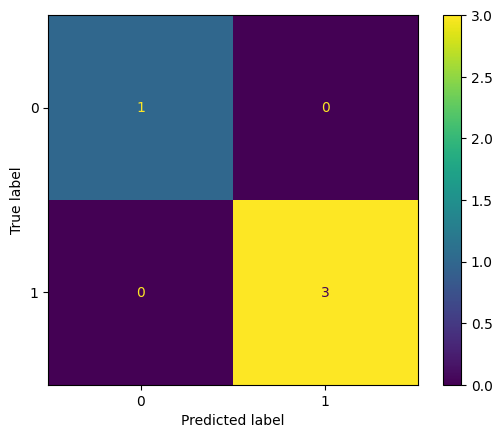

In [ ]:
cmd = ConfusionMatrixDisplay(cm)
cmd.plot()

In [ ]:
from sklearn.metrics import accuracy_score
score = accuracy_score(y_test, y_pred)
score

1.0

In [ ]:
from sklearn.metrics import classification_report
cr = classification_report(y_test, y_pred)
print(cr)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         3

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



In [ ]:
import pickle

# dump() --- to save object

pickle.dump(knn,open('knn_model.sav', 'wb'))

In [ ]:
pickle.dump(scaler, open('scaler_knn.sav', 'wb'))

In [ ]:
pip list

Package                               Version
------------------------------------- ------------------
absl-py                               1.4.0
accelerate                            1.14.0
access                                1.1.10.post3
affine                                3.0.1
aiofiles                              25.1.0
aiohappyeyeballs                      2.7.1
aiohttp                               3.14.3
aiosignal                             1.4.0
aiosqlite                             0.22.1
alabaster                             1.0.0
albucore                              0.0.24
albumentations                        2.0.8
ale-py                                0.12.1
altair                                5.5.0
annotated-doc                         0.0.5
annotated-types                       0.8.0
antlr4-python3-runtime                4.9.3
anyio                                 4.14.2
anywidget                             0.9.21
apsw                                  3.53.4.0

In [ ]:
print(knn.predict(scaler.transform([[22,0,2,0]])))

[0]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [ ]:
print(knn.predict(scaler.transform([[35,3,5,4]])))

[0]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
